Image shape: (1043, 981)
Data type: int32
Minimum: -2
Maximum: 65


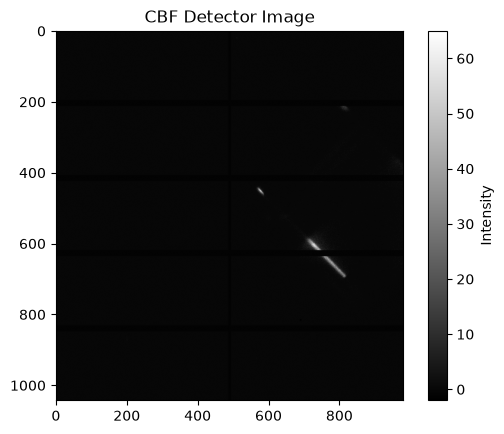

In [27]:
import fabio
import matplotlib.pyplot as plt

# Open the CBF image file
path = "../data/Mainz_2022-10_AXO-Optics-Scan-forML/Mainz_20220131_01_AXO-Optics-Scan-forML_250W_Al-tape_noFlTu_SourceDet-236cm/image_0000001.cbf"
image = fabio.open(path)

# Extract pixel values
data = image.data

print("Image shape:", data.shape)
print("Data type:", data.dtype)
print("Minimum:", data.min())
print("Maximum:", data.max())

# Display image
plt.imshow(data, cmap="gray")
plt.colorbar(label="Intensity")
plt.title("CBF Detector Image")
plt.show()

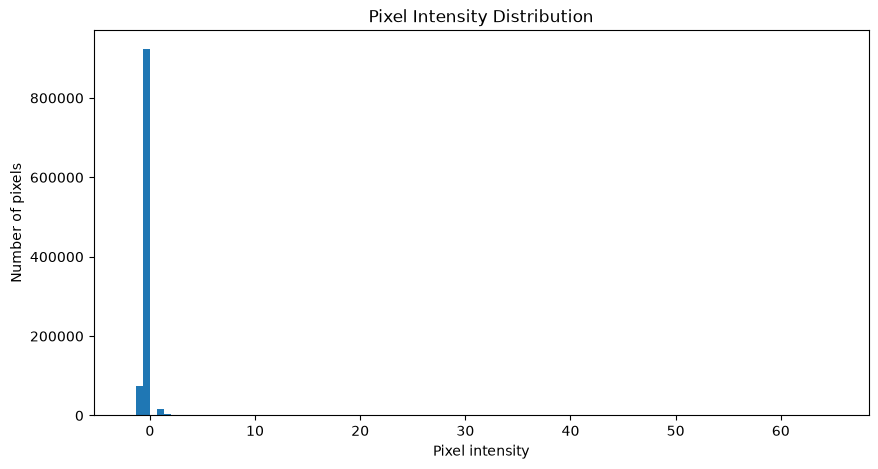

In [28]:
plt.figure(figsize=(10, 5))

plt.hist(data.ravel(), bins=100)

plt.xlabel("Pixel intensity")
plt.ylabel("Number of pixels")
plt.title("Pixel Intensity Distribution")

plt.show()

In [29]:
import numpy as np
# Bin 4x4 pixels into one pixel
def bin_image(image, bin_size=4):
    h, w = image.shape
    h = h // bin_size * bin_size
    w = w // bin_size * bin_size

    image = image[:h, :w]

    return image.reshape(
        h // bin_size, bin_size,
        w // bin_size, bin_size
    ).sum(axis=(1, 3)).astype(np.float32)
# bin the image with a bin size of 4
binned = bin_image(data, bin_size=8)
print(binned.shape)

(130, 122)


In [30]:
binned = bin_image(data, bin_size=12)
print(binned.shape)

(86, 81)


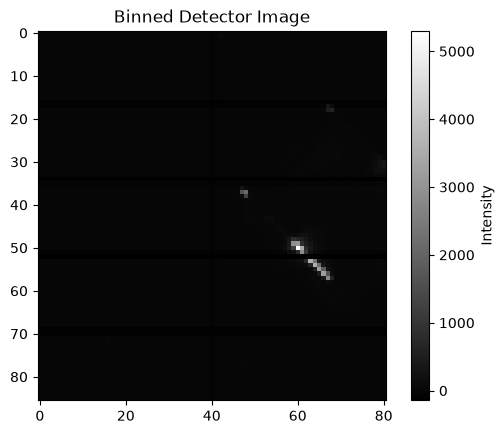

In [31]:
plt.imshow(binned, cmap="gray")
plt.colorbar(label="Intensity")
plt.title("Binned Detector Image")
plt.show()

In [32]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
scaler = MinMaxScaler()
shape = binned.shape
binned_scaled = scaler.fit_transform(binned.reshape(-1, 1)).reshape(shape)

In [33]:
print("Binned and scaled image shape:", binned_scaled.shape)
print("Minimum:", binned_scaled.min())
print("Maximum:", binned_scaled.max())

Binned and scaled image shape: (86, 81)
Minimum: 0.0
Maximum: 0.99999994


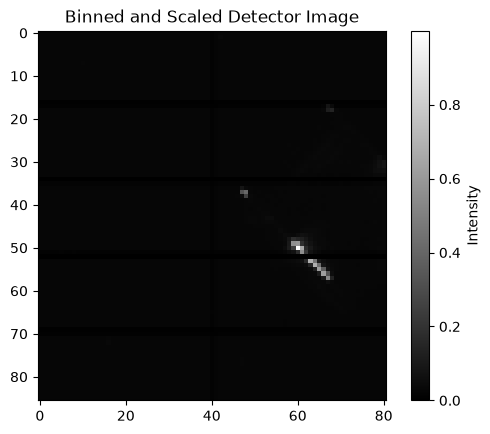

In [34]:
plt.imshow(binned_scaled, cmap="gray")
plt.colorbar(label="Intensity")
plt.title("Binned and Scaled Detector Image")
plt.show()

Image 130 shape: (1043, 981)
Image 160 shape: (1043, 981)


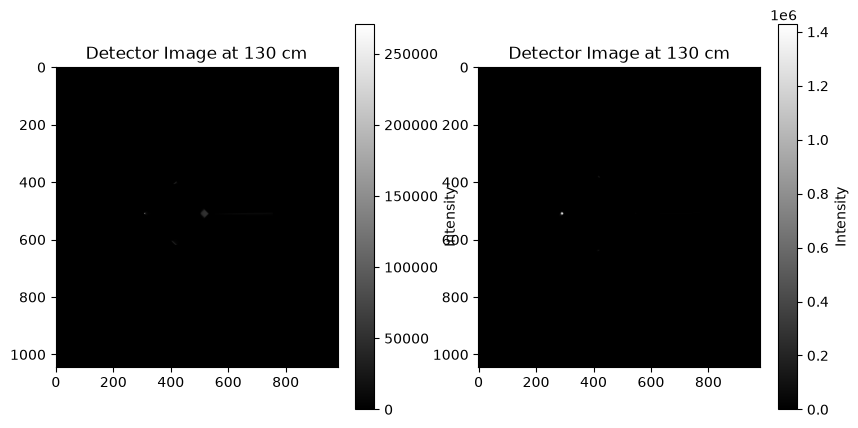

In [35]:
path_130 = "../data/Mainz_2022-10_AXO-Optics-Scan-forML/Mainz_20220912_02_AXO-Optics-Scan-forML_245W_Al-tape_noFlTu_SourceDet-130cm_detPos1/image_0008737.cbf"
path_160 = "../data/Mainz_2022-10_AXO-Optics-Scan-forML/Mainz_20220912_02_AXO-Optics-Scan-forML_245W_Al-tape_noFlTu_SourceDet-130cm_detPos1/image_0004497.cbf"

image_130 = fabio.open(path_130)
image_160 = fabio.open(path_160)

data_130 = image_130.data
data_160 = image_160.data

print("Image 130 shape:", data_130.shape)
print("Image 160 shape:", data_160.shape)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(data_130, cmap="gray")
plt.colorbar(label="Intensity")
plt.title("Detector Image at 130 cm")

plt.subplot(1, 2, 2)
plt.imshow(data_160, cmap="gray")
plt.colorbar(label="Intensity")
plt.title("Detector Image at 130 cm")
plt.show()

Image: image_0008737.cbf
Shape: (1043, 981)
Brightest pixel: x=309, z=509
Maximum intensity: 270621.0


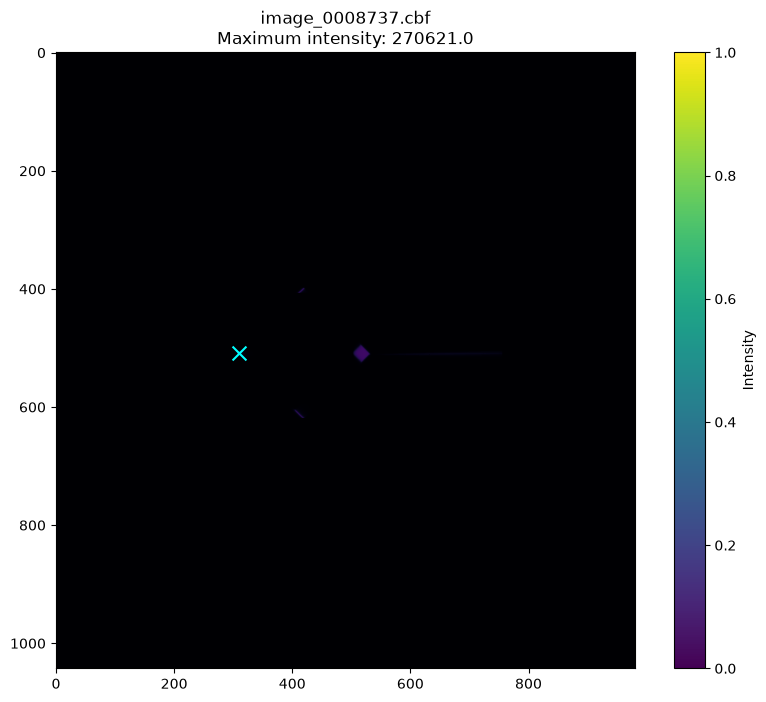


--- Highest maximum intensity ---
Image: ../data/Mainz_2022-10_AXO-Optics-Scan-forML/Mainz_20220912_02_AXO-Optics-Scan-forML_245W_Al-tape_noFlTu_SourceDet-130cm_detPos1/image_0004497.cbf
Brightest pixel (x, z): (np.int64(290), np.int64(508))
Maximum intensity: 1427582.0


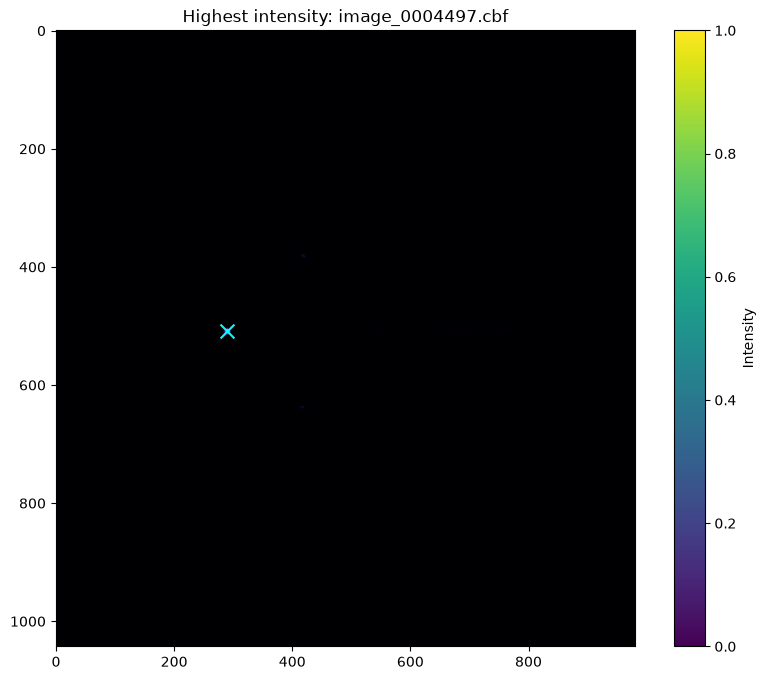

In [36]:
from pathlib import Path

import fabio
import matplotlib.pyplot as plt
import numpy as np


# Path to your example image
path_130 = Path(
    "../data/Mainz_2022-10_AXO-Optics-Scan-forML/"
    "Mainz_20220912_02_AXO-Optics-Scan-forML_245W_Al-tape_noFlTu_SourceDet-130cm_detPos1/"
    "image_0008737.cbf"
)


def find_brightest_point(image):
    """Return x, z coordinates and maximum intensity."""
    z, x = np.unravel_index(np.argmax(image), image.shape)
    return x, z, float(image[z, x])


def inspect_image(image_path):
    image = fabio.open(str(image_path)).data
    x, z, intensity = find_brightest_point(image)

    print(f"Image: {image_path.name}")
    print(f"Shape: {image.shape}")
    print(f"Brightest pixel: x={x}, z={z}")
    print(f"Maximum intensity: {intensity}")

    plt.figure(figsize=(10, 8))
    plt.imshow(image, cmap="inferno", origin="upper")
    plt.scatter(x, z, color="cyan", marker="x", s=100)
    plt.title(f"{image_path.name}\nMaximum intensity: {intensity}")
    plt.colorbar(label="Intensity")
    plt.show()


def find_optimal_image(folder):
    """Find the image with the highest single-pixel intensity."""
    image_paths = sorted(Path(folder).glob("*.cbf"))

    if not image_paths:
        raise FileNotFoundError(f"No CBF images found in {folder}")

    best_path = None
    best_intensity = -np.inf
    best_point = None

    for image_path in image_paths:
        image = fabio.open(str(image_path)).data
        x, z, intensity = find_brightest_point(image)

        if intensity > best_intensity:
            best_path = image_path
            best_intensity = intensity
            best_point = (x, z)

    print("\n--- Highest maximum intensity ---")
    print(f"Image: {best_path}")
    print(f"Brightest pixel (x, z): {best_point}")
    print(f"Maximum intensity: {best_intensity}")

    # Plot the winning image
    best_image = fabio.open(str(best_path)).data
    plt.figure(figsize=(10, 8))
    plt.imshow(best_image, cmap="inferno", origin="upper")
    plt.scatter(*best_point, color="cyan", marker="x", s=100)
    plt.title(f"Highest intensity: {best_path.name}")
    plt.colorbar(label="Intensity")
    plt.show()

    return best_path, best_point, best_intensity


# 1. Inspect the example image
inspect_image(path_130)

# 2. Search the folder for the highest-intensity image
best_path, best_point, best_intensity = find_optimal_image(path_130.parent)

In [37]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

file_path = "../data/preprocessed_dataset.h5"
with h5py.File(file_path, "r") as f:
    print("Number of data points:", len(f))
    print("Image shape:", f["data_point_0"]["image"].shape)

Number of data points: 61105
Image shape: (86, 81)


In [38]:
x_min = float("inf")
x_max = float("-inf")
z_min = float("inf")
z_max = float("-inf")

with h5py.File(file_path, "r") as f:
    for name in f:
        x = f[name]["x_offset"][()]
        z = f[name]["z_offset"][()]

        x_min = min(x_min, x)
        x_max = max(x_max, x)
        z_min = min(z_min, z)
        z_max = max(z_max, z)

print(f"X offset: min = {x_min}, max = {x_max}")
print(f"Z offset: min = {z_min}, max = {z_max}")

X offset: min = -0.48039999999999994, max = 0.5605
Z offset: min = -0.5204, max = 0.5403


In [39]:
with h5py.File(file_path, "r") as f:
    for i, name in enumerate(f):
        if i >= 5:
            break

        x = f[name]["x_offset"][()]
        z = f[name]["z_offset"][()]

        print(f"{name}: x_offset={x}, z_offset={z}")

data_point_0: x_offset=-0.43970000000000004, z_offset=-0.5201
data_point_1: x_offset=-0.4399, z_offset=-0.5101
data_point_10: x_offset=-0.44, z_offset=-0.42010000000000014
data_point_100: x_offset=-0.44010000000000005, z_offset=0.4799
data_point_1000: x_offset=-0.3502, z_offset=0.3899999999999999
